In [8]:
import os, sys, subprocess
import warnings
warnings.filterwarnings('ignore')

REPO_URL = 'https://github.com/durak-dev/ImageClassification.git'
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    # Colab starts with an empty VM: clone the repo (code AND data live in it).
    # On later runs the folder already exists, so just pull the newest commits.
    ROOT = '/content/ImageClassification'
    if not os.path.exists(ROOT):
        subprocess.run(['git', 'clone', REPO_URL, ROOT], check=True)
    else:
        subprocess.run(['git', '-C', ROOT, 'pull'], check=True)
else:
    # Local: the notebook sits in the project root, but also work if it was
    # started from a subfolder.
    cwd = os.path.abspath(os.getcwd())
    ROOT = cwd if os.path.isdir(os.path.join(cwd, 'utils')) else os.path.dirname(cwd)

os.chdir(ROOT)
sys.path.insert(0, ROOT)          # so `import utils.funcs` finds OUR utils folder

DATA_DIR = os.path.join(ROOT, 'data')
ORIG_DIR = os.path.join(DATA_DIR, 'original')            # raw images/ + labels/ (placed manually, never modified)
MANIFEST_PATH = os.path.join(DATA_DIR, 'split_manifest.csv')   # which file belongs to which split
SEED = 42
print('Running on:', 'Google Colab' if IN_COLAB else 'local machine')
print('Project root:', ROOT)

Running on: Google Colab
Project root: /content/ImageClassification


In [2]:
import importlib
import utils.funcs
importlib.reload(utils.funcs)      # pick up edits to funcs.py without restarting
from utils.funcs import *
from utils import config, github_sync
from utils.github_sync import save_csv, load_csv, push_files
from utils.MoE import *

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

In [3]:
# Recreate data/{split}/ with the corrected images + labels if they are missing (fresh Colab VM).
# Needs split_manifest.csv, data/original/ and the two checkpoint files from the cloned repo.
if not all(os.path.exists(os.path.join(split_dir(DATA_DIR, s, 'labels'), CORRECTED_LABELS_FILE)) for s in SPLITS):
    materialize_splits(ORIG_DIR, DATA_DIR, pd.read_csv(MANIFEST_PATH))
    rebuild_corrected(pd.read_csv(os.path.join(ROOT, 'checkpoints', 'df_fixed.csv')), DATA_DIR,
                      labels_corrected=pd.read_csv(os.path.join(ROOT, 'checkpoints', 'labels_corrected.csv')))

train: 42000 images
val  : 9000 images
test : 9000 images
test : 9000 images written, 3720 of 9000 corrected -> /content/ImageClassification/data/test/images_corrected
train: 42000 images written, 17460 of 42000 corrected -> /content/ImageClassification/data/train/images_corrected
val  : 9000 images written, 3905 of 9000 corrected -> /content/ImageClassification/data/val/images_corrected
labels_corrected.csv written for test, train, val


In [4]:
dfs = {s: pd.read_csv(os.path.join(split_dir(DATA_DIR, s, "labels"), CORRECTED_LABELS_FILE)) for s in ["train", "val", "test"]}
classes = sorted(dfs["train"]["class_id"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}

In [5]:
SIZE, BATCH, AUTOTUNE = 64, 128, tf.data.AUTOTUNE

def load(path, y):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    return tf.image.resize(img, (SIZE, SIZE)), y

def make_ds(split, shuffle):
    df = dfs[split]
    paths = (f"{DATA_DIR}/{split}/images_corrected/" + df["filename"].astype(str)).values
    labels = df["class_id"].map(class_to_idx)
    assert labels.notna().all(), f"{split} has labels not present in train"
    ds = tf.data.Dataset.from_tensor_slices((paths, labels.values.astype("int32")))
    if shuffle:
        ds = ds.shuffle(len(df), seed=SEED)
    return ds.map(load, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

train, val, test = make_ds("train", True), make_ds("val", False), make_ds("test", False)
print(len(classes), "classes")
print(dfs["train"]["filename"].iloc[0], os.path.exists(f"{DATA_DIR}/train/images_corrected/" + str(dfs["train"]["filename"].iloc[0])))
for x, y in train.take(1):
    print(x.shape, x.dtype, float(tf.reduce_min(x)), float(tf.reduce_max(x)))

200 classes
image_000002.JPEG True
(128, 64, 64, 3) <dtype: 'float32'> 0.0 255.0


## Experiments

Three runs with the same backbone and settings, logs saved as `history_logs/<model>_<epochs>epochs_<base|aug>.csv`:

1. backbone with a plain dense head (no mixture), no augmentation
2. MoE, no augmentation
3. MoE, with augmentation

In [6]:
EPOCHS, N_EXPERTS = 60, 20
HISTORY_DIR = 'history_logs'      # local folder; on Colab each log is also committed to GitHub under this name

# on Colab the VM disk disappears, so the logs are committed to the repo (asks for the token once)
if IN_COLAB:
    config.ensure_github()
USE_GITHUB = IN_COLAB and config.github_ready()
print('History logs ->', 'GitHub' if USE_GITHUB else f'local folder {HISTORY_DIR}/')

aug = tf.keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomTranslation(0.1, 0.1)])


def run(model, name, gate=False):
    """Train with the default callbacks, then save the log as history_logs/<name>.csv."""
    cbs, mon = default_callbacks(val, name=name, log_dir=HISTORY_DIR, gate=gate)
    history = model.fit(train, validation_data=val, epochs=EPOCHS, callbacks=cbs)
    if USE_GITHUB:
        push_files({f'{HISTORY_DIR}/{name}.csv': os.path.join(HISTORY_DIR, f'{name}.csv')}, f'history log: {name}')
    plot_history(history)
    return history, mon

History logs -> GitHub


### 1. Backbone only

In [10]:
def default_callbacks(val_ds, name="model", log_dir="history_logs", patience=8, gate=False):
    """Standard callbacks for fit(): val macro-F1, a per-epoch history CSV
    (log_dir/<name>.csv, survives a crashed Colab session) and early stopping.
    gate=True also adds GateMonitor (MoE only). Returns (callbacks, gate_monitor or None).
    MacroF1 must come before CSVLogger so that val_f1 ends up in the CSV."""
    os.makedirs(log_dir, exist_ok=True)
    mon = GateMonitor(val_ds) if gate else None
    cbs = ([mon] if gate else []) + [
        MacroF1(val_ds),
        tf.keras.callbacks.CSVLogger(os.path.join(log_dir, f"{name}.csv")),
        tf.keras.callbacks.EarlyStopping(patience=patience, restore_best_weights=True)]
    return cbs, mon

Epoch 1/60
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.0324 - loss: 5.0481  val macro-F1 0.0110
329/329 ━━━━━━━━━━━━━━━━━━━━ 95s 187ms/step - accuracy: 0.0469 - loss: 4.8876 - val_accuracy: 0.0374 - val_loss: 5.0245 - val_f1: 0.0110
Epoch 2/60
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.0722 - loss: 4.6301  val macro-F1 0.0335
329/329 ━━━━━━━━━━━━━━━━━━━━ 84s 93ms/step - accuracy: 0.0797 - loss: 4.5791 - val_accuracy: 0.0799 - val_loss: 4.5640 - val_f1: 0.0335
Epoch 3/60
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.0955 - loss: 4.4477  val macro-F1 0.0492
329/329 ━━━━━━━━━━━━━━━━━━━━ 29s 89ms/step - accuracy: 0.0992 - loss: 4.4204 - val_accuracy: 0.1052 - val_loss: 4.3932 - val_f1: 0.0492
Epoch 4/60
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.1111 - loss: 4.3244  val macro-F1 0.0450
329/329 ━━━━━━━━━━━━━━━━━━━━ 42s 91ms/step - accuracy: 0.1135 - loss: 4.3068 - val_accuracy: 0.0872 - val_loss: 4.5185 - val_f1: 0.0450
Epoch 5/60
328/329 ━━━

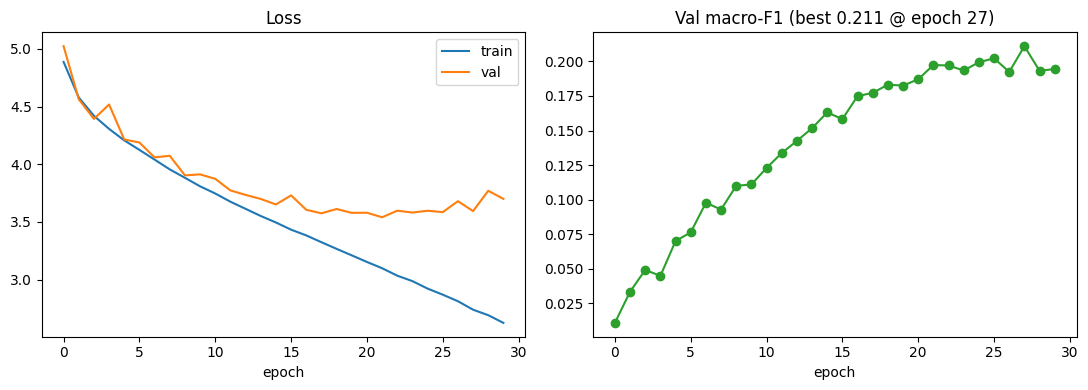

In [11]:
tf.keras.backend.clear_session()
cnn = build_cnn(SIZE, len(classes), n_experts=N_EXPERTS)
hist_cnn, _ = run(cnn, f'cnn_{EPOCHS}epochs_base')

### 2. MoE without augmentation

Epoch 1/60
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - accuracy: 0.0295 - loss: 5.1384  usage [0.04 0.02 0.15 0.01 0.04 0.02 0.01 0.01 0.07 0.15 0.1  0.01 0.01 0.01
 0.05 0.14 0.01 0.02 0.03 0.07]  wins [ 50  45 538  13   1   0   3   0 182 757 394   0   0   1   6 369   1   0
   0 200]
  val macro-F1 0.0058
329/329 ━━━━━━━━━━━━━━━━━━━━ 96s 189ms/step - accuracy: 0.0414 - loss: 5.0031 - val_accuracy: 0.0240 - val_loss: 5.2982 - val_f1: 0.0058
Epoch 2/60
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.0602 - loss: 4.7617  usage [0.07 0.05 0.06 0.03 0.09 0.03 0.09 0.06 0.04 0.06 0.07 0.02 0.06 0.04
 0.03 0.05 0.03 0.05 0.02 0.05]  wins [238  90 124  57 417   5 346 161  15 208 257   5 169  41  49  48  40 115
   7 168]
  val macro-F1 0.0240
329/329 ━━━━━━━━━━━━━━━━━━━━ 32s 97ms/step - accuracy: 0.0668 - loss: 4.7145 - val_accuracy: 0.0623 - val_loss: 4.7741 - val_f1: 0.0240
Epoch 3/60
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.0838 - loss: 4.5726  usage [0.04 0.04 0.05 

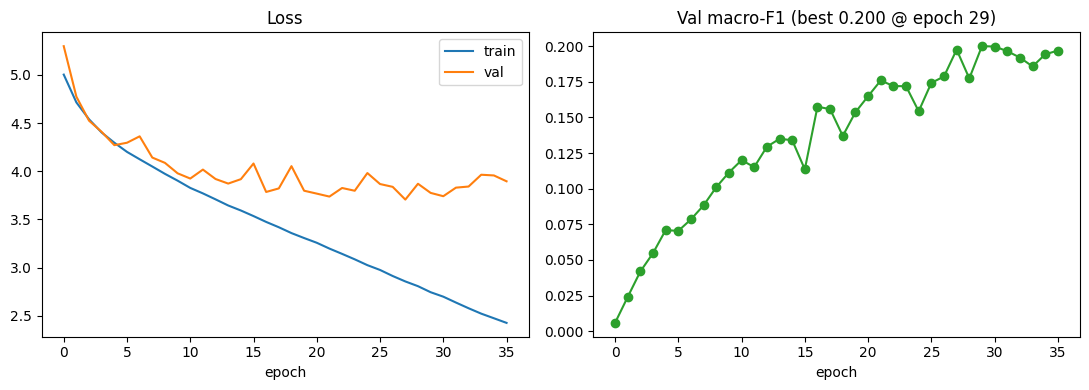

In [12]:
tf.keras.backend.clear_session()
moe_base = build_moe(SIZE, len(classes), n_experts=N_EXPERTS, balance=0.05)
hist_base, mon_base = run(moe_base, f'moe_{EPOCHS}epochs_base', gate=True)

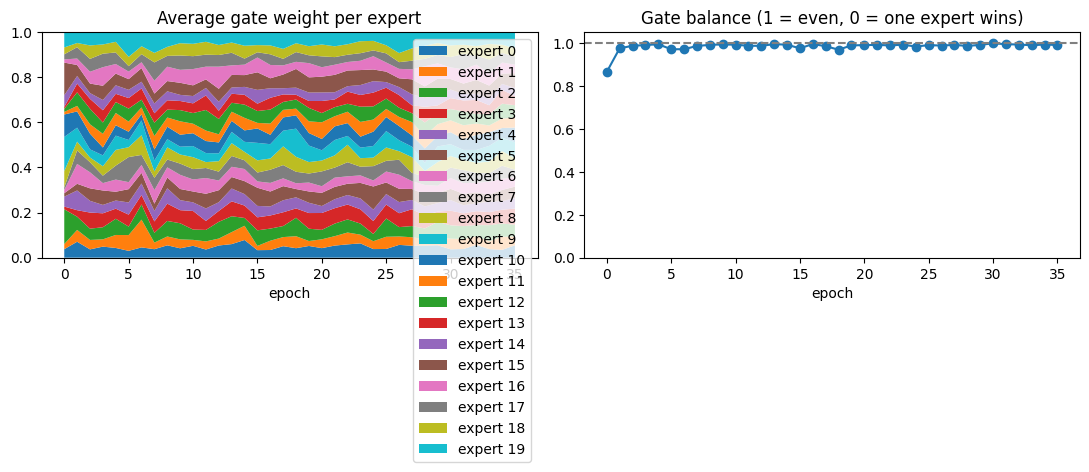

In [15]:
mon = mon_base
usage = np.array(mon.usage)                      # (epochs, experts)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].stackplot(range(len(usage)), usage.T, labels=[f"expert {i}" for i in range(usage.shape[1])])
ax[0].set(title="Average gate weight per expert", xlabel="epoch", ylim=(0, 1))
ax[0].legend(loc="upper right")

ax[1].plot(mon.entropy, marker="o")
ax[1].axhline(1, ls="--", c="gray")
ax[1].set(title="Gate balance (1 = even, 0 = one expert wins)", xlabel="epoch", ylim=(0, 1.05))
plt.tight_layout(); plt.show()

### 3. MoE with augmentation

Epoch 1/60
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 186ms/step - accuracy: 0.0276 - loss: 5.1270  usage [0.15 0.02 0.09 0.18 0.03 0.02 0.01 0.01 0.04 0.01 0.03 0.05 0.07 0.02
 0.05 0.04 0.02 0.04 0.09 0.04]  wins [ 561    0    6 1107   83    2    1    1   46    7    6   32  117   59
  146   64   11   85  215   11]
  val macro-F1 0.0076
329/329 ━━━━━━━━━━━━━━━━━━━━ 92s 210ms/step - accuracy: 0.0385 - loss: 5.0056 - val_accuracy: 0.0242 - val_loss: 5.1879 - val_f1: 0.0076
Epoch 2/60
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - accuracy: 0.0580 - loss: 4.8043  usage [0.03 0.05 0.04 0.04 0.12 0.03 0.06 0.04 0.04 0.08 0.05 0.02 0.05 0.01
 0.04 0.06 0.07 0.11 0.02 0.04]  wins [ 32 137 119  65 582  70 110 129  53 160 144  35  94   1  92 142 123 361
  12  99]
  val macro-F1 0.0231
329/329 ━━━━━━━━━━━━━━━━━━━━ 65s 198ms/step - accuracy: 0.0620 - loss: 4.7606 - val_accuracy: 0.0676 - val_loss: 4.7539 - val_f1: 0.0231
Epoch 3/60
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - accuracy: 0.0776 - loss: 4.6352 

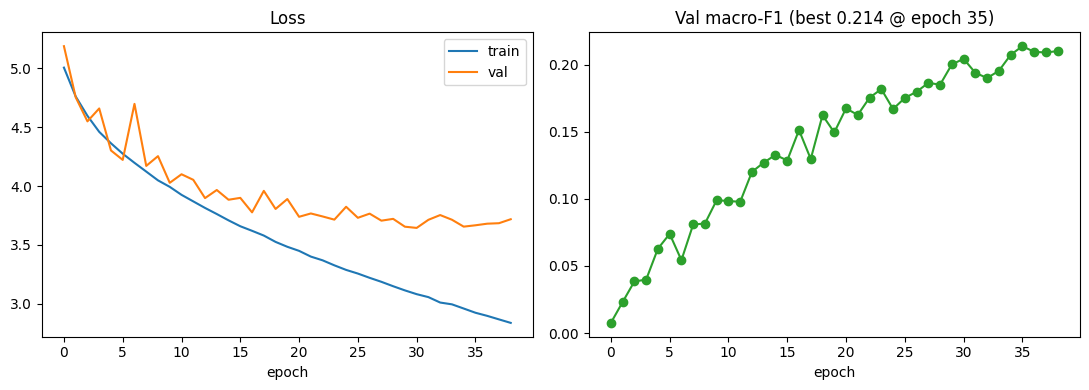

In [13]:
tf.keras.backend.clear_session()
moe_aug = build_moe(SIZE, len(classes), n_experts=N_EXPERTS, balance=0.05, augmentation=aug)
hist_aug, mon_aug = run(moe_aug, f'moe_{EPOCHS}epochs_aug', gate=True)

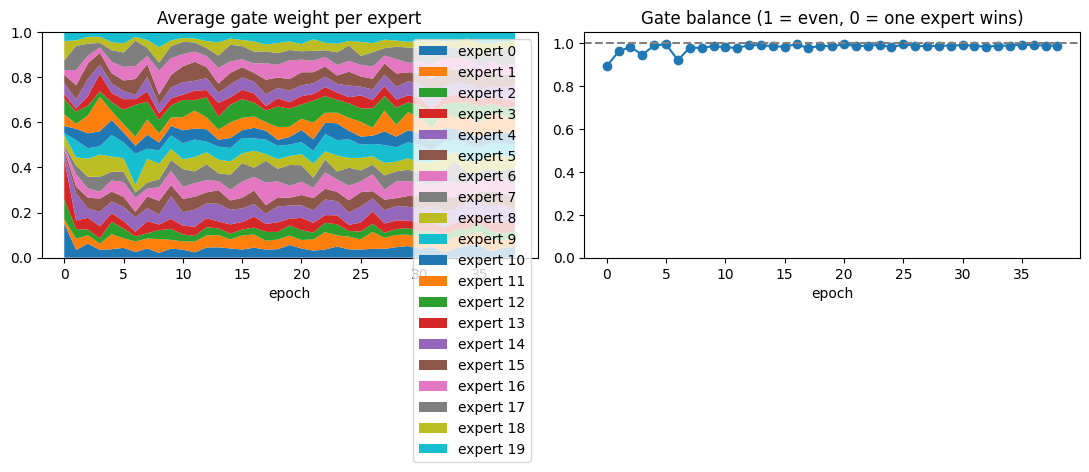

In [14]:
mon = mon_aug        # or mon_base
usage = np.array(mon.usage)                      # (epochs, experts)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].stackplot(range(len(usage)), usage.T, labels=[f"expert {i}" for i in range(usage.shape[1])])
ax[0].set(title="Average gate weight per expert", xlabel="epoch", ylim=(0, 1))
ax[0].legend(loc="upper right")

ax[1].plot(mon.entropy, marker="o")
ax[1].axhline(1, ls="--", c="gray")
ax[1].set(title="Gate balance (1 = even, 0 = one expert wins)", xlabel="epoch", ylim=(0, 1.05))
plt.tight_layout(); plt.show()

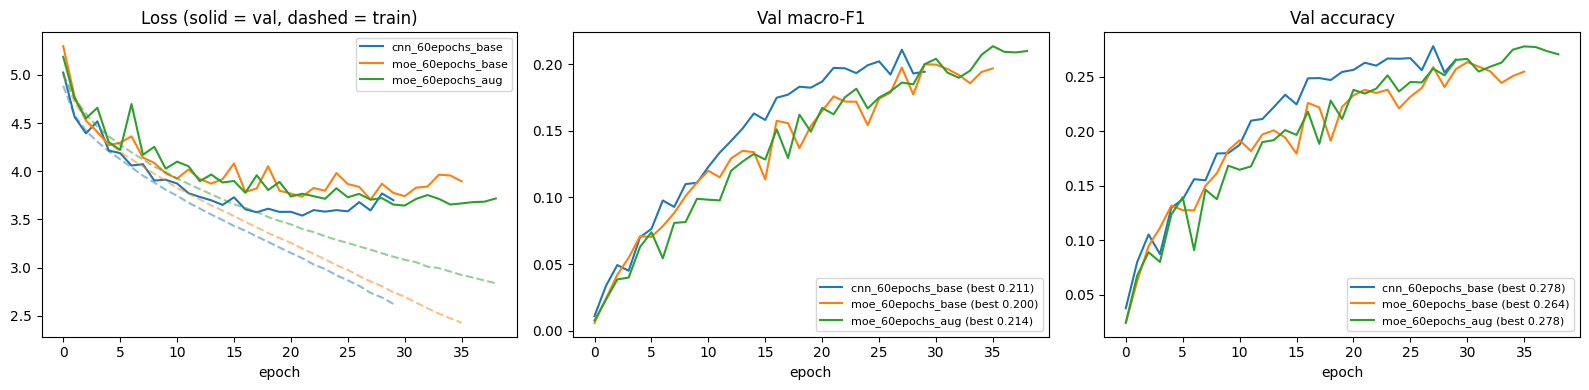

In [16]:
runs = [f"cnn_{EPOCHS}epochs_base", f"moe_{EPOCHS}epochs_base", f"moe_{EPOCHS}epochs_aug"]
logs = {r: pd.read_csv(os.path.join(HISTORY_DIR, f"{r}.csv")) for r in runs}

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for i, (name, h) in enumerate(logs.items()):
    ax[0].plot(h["val_loss"], color=f"C{i}", label=name)
    ax[0].plot(h["loss"], color=f"C{i}", ls="--", alpha=0.5)       # dashed = train loss
    ax[1].plot(h["val_f1"], color=f"C{i}", label=f"{name} (best {h['val_f1'].max():.3f})")
    ax[2].plot(h["val_accuracy"], color=f"C{i}", label=f"{name} (best {h['val_accuracy'].max():.3f})")
ax[0].set(title="Loss (solid = val, dashed = train)", xlabel="epoch")
ax[1].set(title="Val macro-F1", xlabel="epoch")
ax[2].set(title="Val accuracy", xlabel="epoch")
for a in ax:
    a.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [17]:
os.makedirs('models', exist_ok=True)
weights_path = f'models/moe_{EPOCHS}epochs_aug.weights.h5'
moe_aug.save_weights(weights_path)          # best epoch, because EarlyStopping restores the best weights
print(f'saved {os.path.getsize(weights_path) / 1e6:.1f} MB -> {weights_path}')

if USE_GITHUB:                               # Colab: the VM disk disappears, so commit it as well
    push_files({weights_path: weights_path}, f'model weights: moe_{EPOCHS}epochs_aug')


saved 29.3 MB -> models/moe_60epochs_aug.weights.h5
Uploaded 1 file(s) to durak-dev/ImageClassification@checkpoints: models/moe_60epochs_aug.weights.h5


In [ ]:
from utils.moe_project.train import run, compare
compare(train_ds, val_ds, size=..., n_classes=...)